In [33]:
import sys
import os
import numpy as np
import pandas as pd

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm
from models import bom

In [34]:
import importlib
importlib.reload(generate_utils)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [35]:
file_ids = list(range(0, 33+1))
# file_ids = [0,   # minrevs
# 			1,   # minswitch
# 			7,   # maxswitch
# 			11,  # median
# 			12,  # maxrevs
# 			17,  # mean
# 			19,  # paper
# 			21]  # clean
# file_ids = [19]
plot_id = 19

weights = (0.1, -0.25, 1.)

neuron_labels = [f'N{i}' for i in range(20)]
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 4

In [36]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(template_ids, filenames_gcamp,
 discrete_states, eigenworms) = read_utils.get_datas(path, file_ids)

for i in range(len(file_ids)):
	# clear nan values
	mask = eigenworms[i].notna().all(axis=1)

	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

# preprocess
pass

In [37]:
# generate
file_ids = template_ids.copy()
filenames = list()
modes = list()
traces_reconstructed = list()
traces_residual = list()
traces = list()
params = list()
params_manifold = list()

for file_id in file_ids:
	(filename,
	 modes_,
	 traces_reconstructed_,
	 traces_residual_,
	 traces_,
	 params_,
	 params_manifold_) = generate_utils.artificialize(weights, 'hgm',
													  filenames_gcamp[file_ids.index(file_id)],
													  neuron_labels,
													  eigenworms[file_ids.index(file_id)],
													  discrete_states[file_ids.index(file_id)][bhl_selection],
													  n_dimensions=len(bhl_selection))

	filenames.append(filename)
	modes.append(modes_)
	traces_reconstructed.append(traces_reconstructed_)
	traces_residual.append(traces_residual_)
	traces.append(traces_)
	params.append(params_)
	params_manifold.append(params_manifold_)

In [38]:
neuron_labels = neuron_labels[:5]
plot_idx = file_ids.index(plot_id)

In [39]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [40]:
save = False

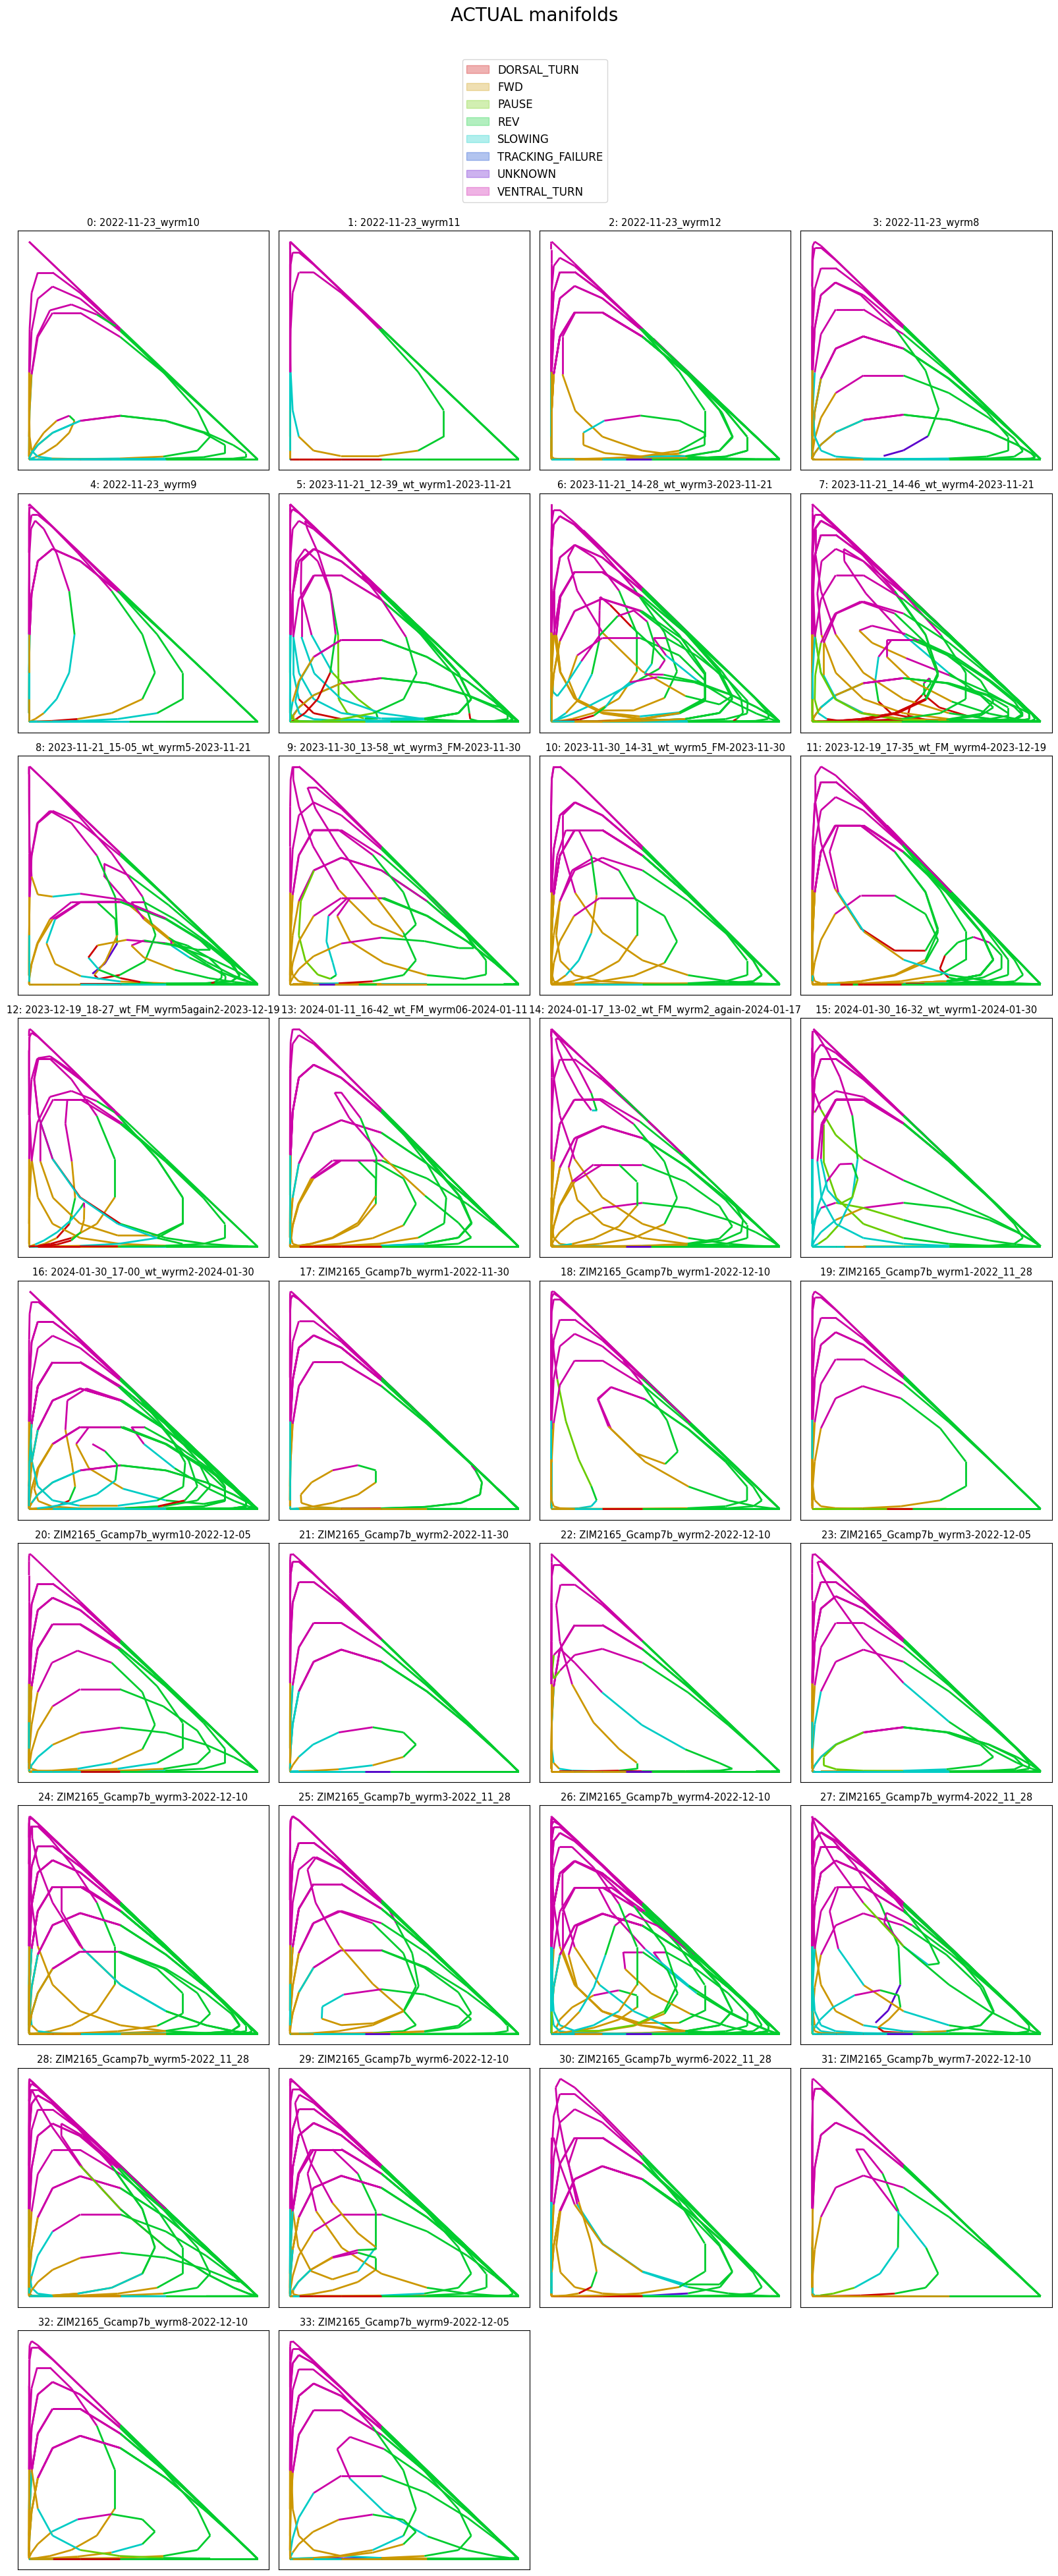

In [41]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes,
						  discrete_states,
						  None, None,
						  title='ACTUAL manifolds', top_space=3.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

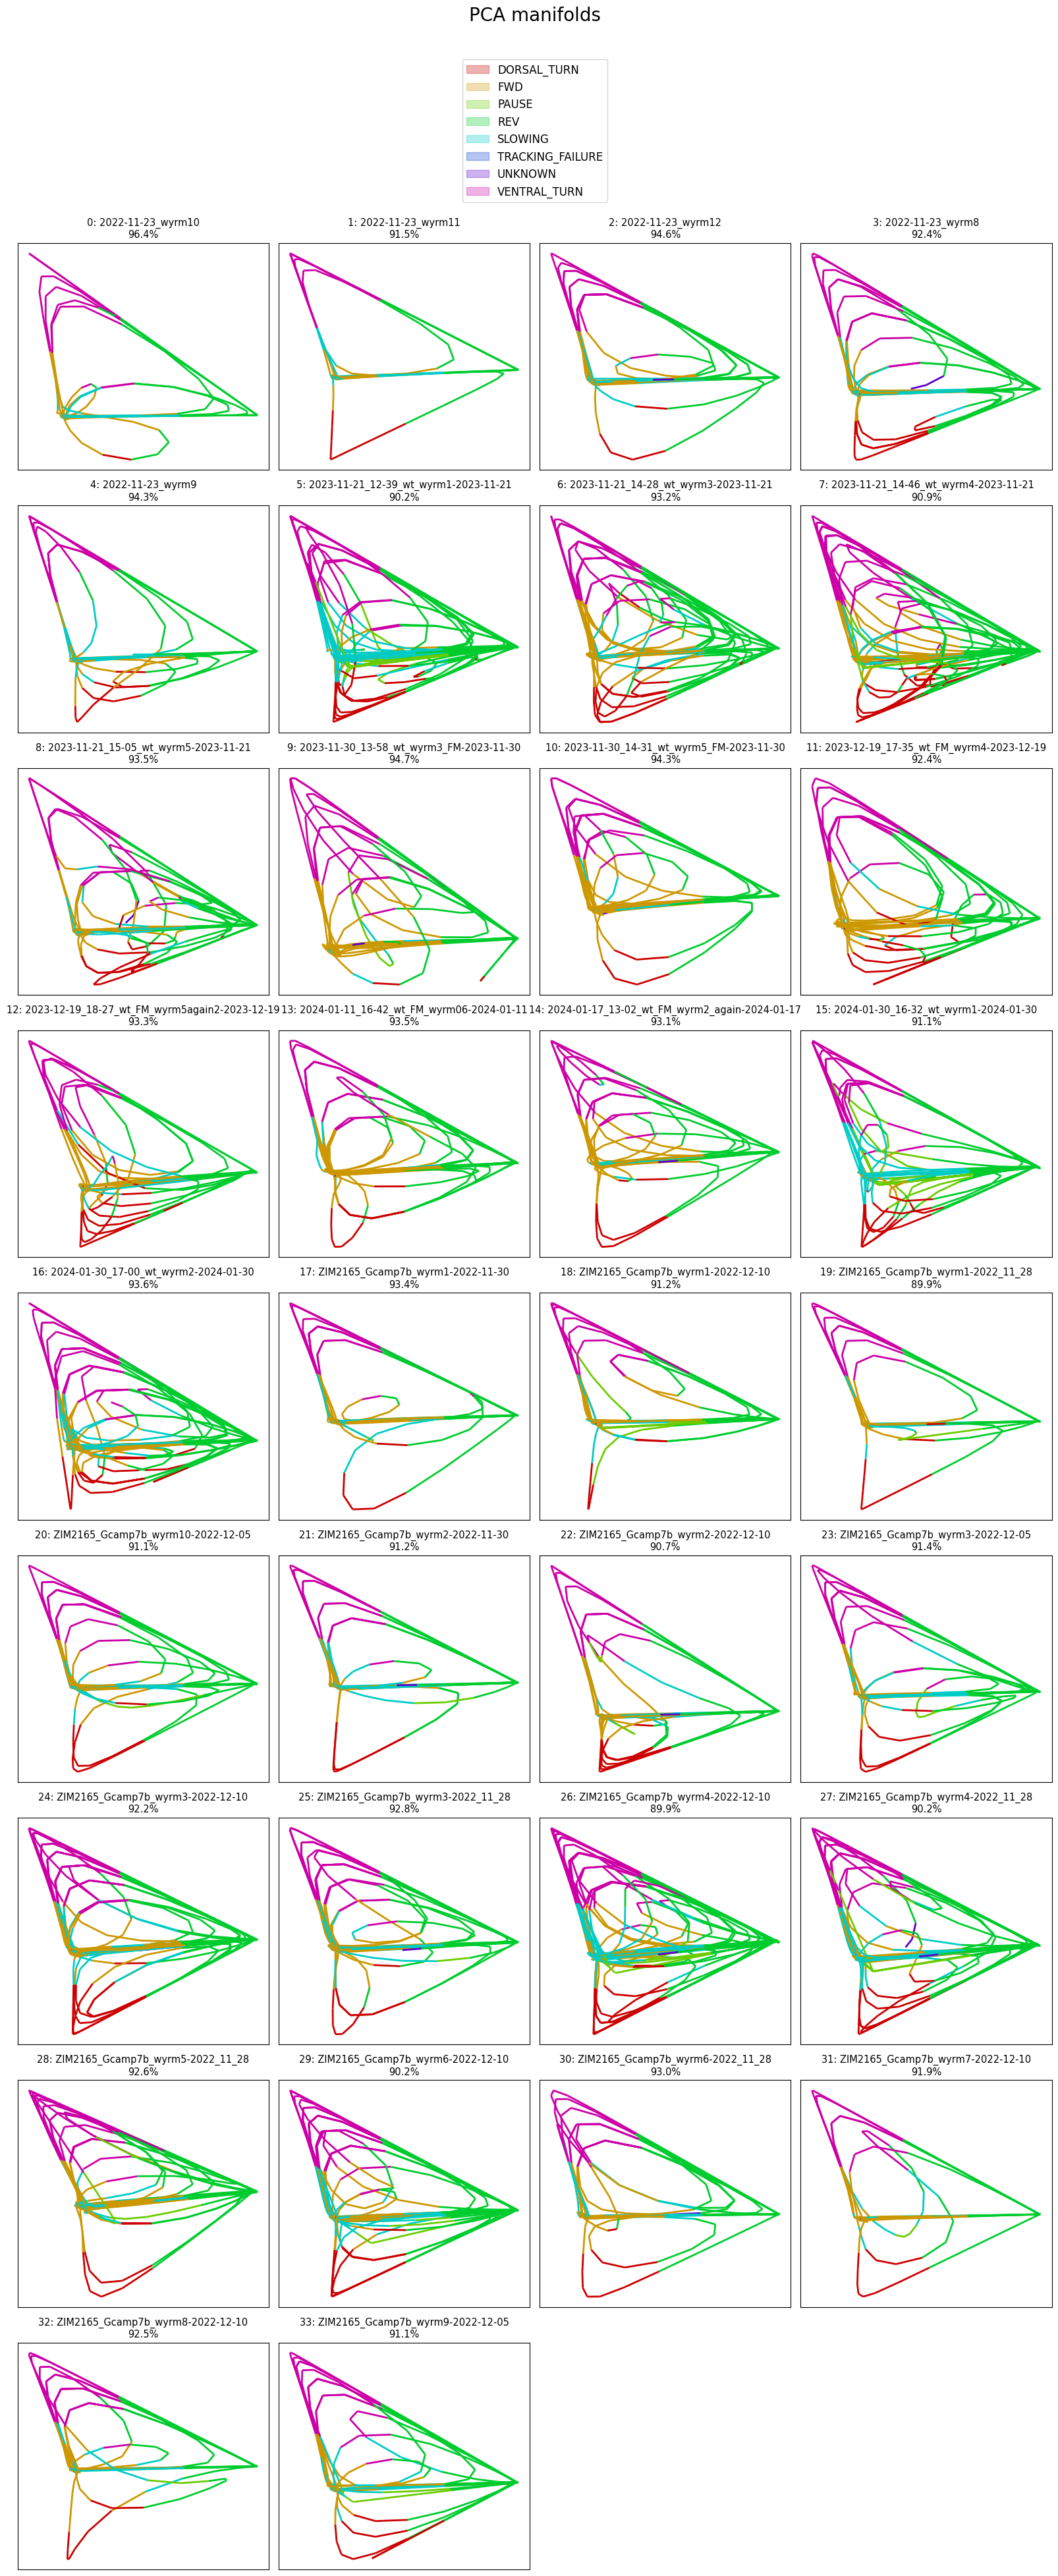

92.3%


In [42]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold,
						  discrete_states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds', top_space=3.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PCA' if save else None)

In [43]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 							 modes_manifold, discrete_states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PCA manifolds', top_space=3.5,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

In [44]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
# 								 modes_manifold, discrete_states,
# 								 [vx[:3] for vx in vars_expl_mans], None,
# 								 titles=['PCA manifolds'] * len(file_ids), top_space=3.5, animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-PCA_3d' if save else None)

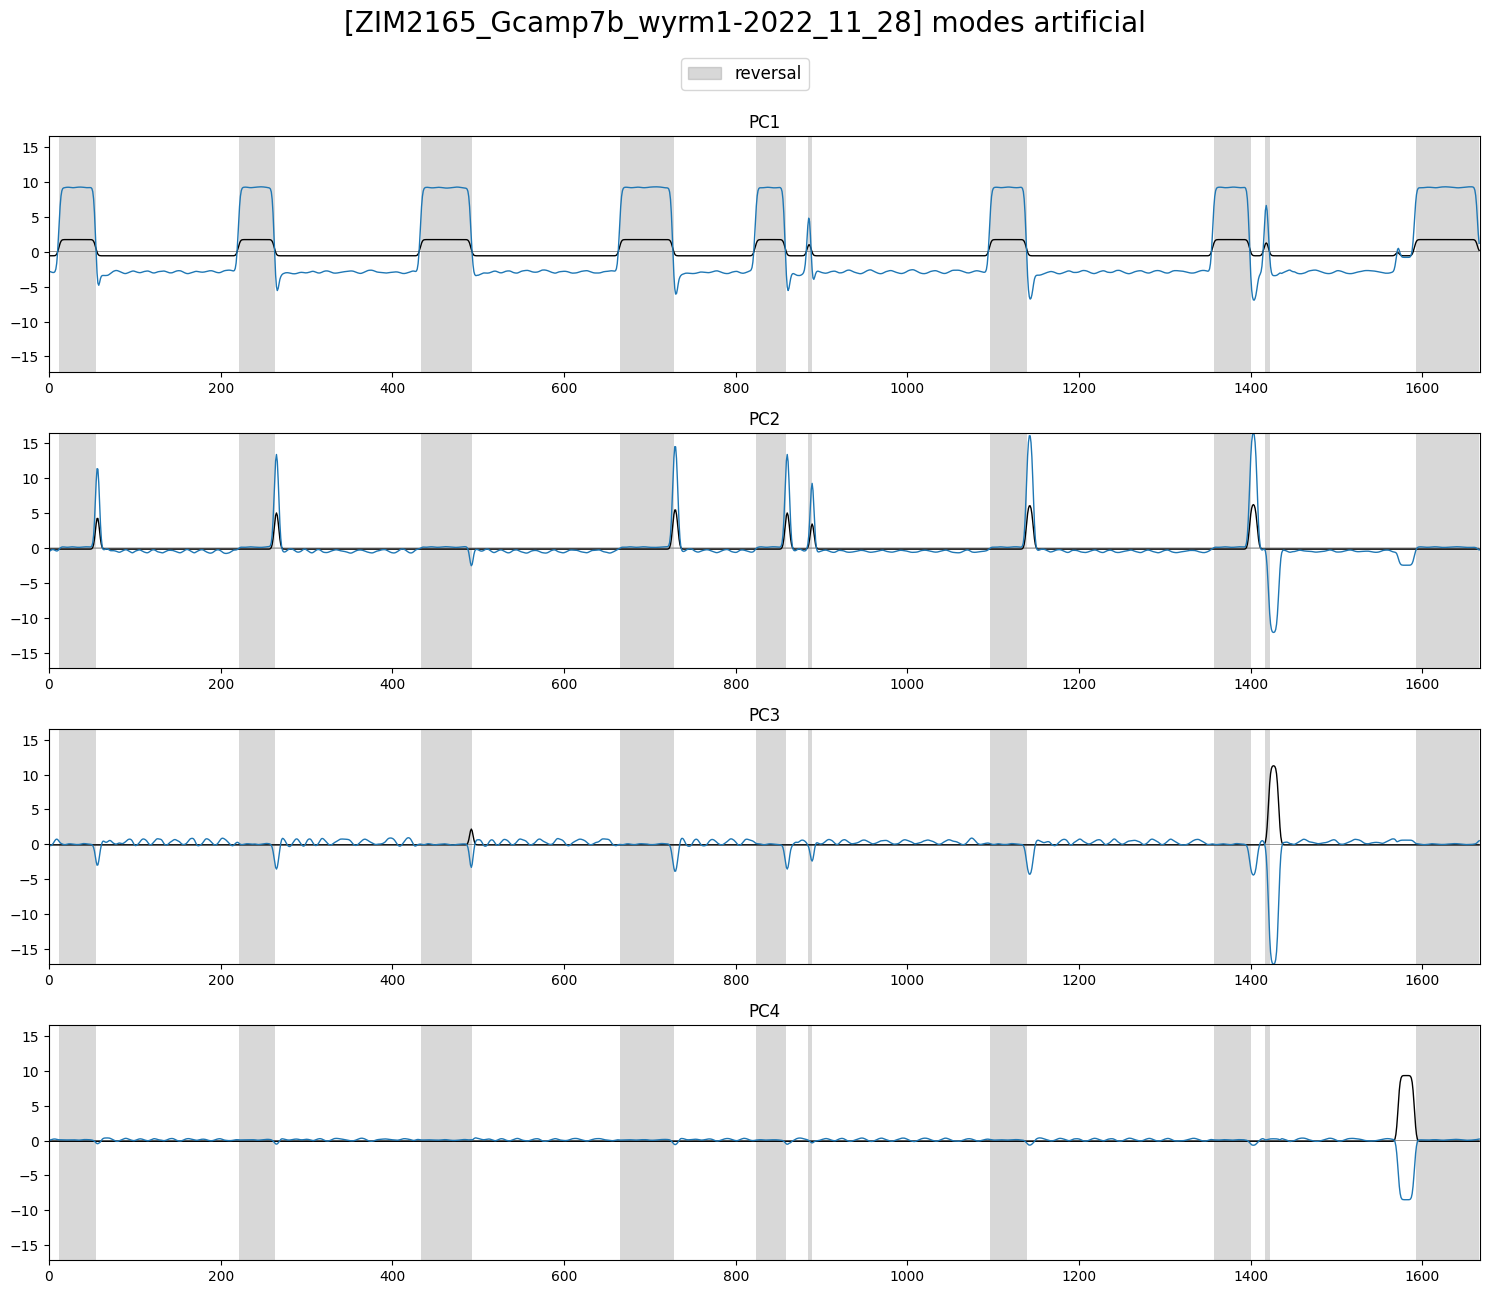

In [45]:
plot_utils.plot_traces([modes[plot_id].set_axis(list([f'PC{i+1}' for i in range(dims)]), axis=1),
						modes_manifold[plot_id]],
					   discrete_states[plot_id][['REV']],
					   label='reversal',
					   title=f'[{filenames[plot_id]}] modes artificial', ylimits=None, plots_per_row=1)

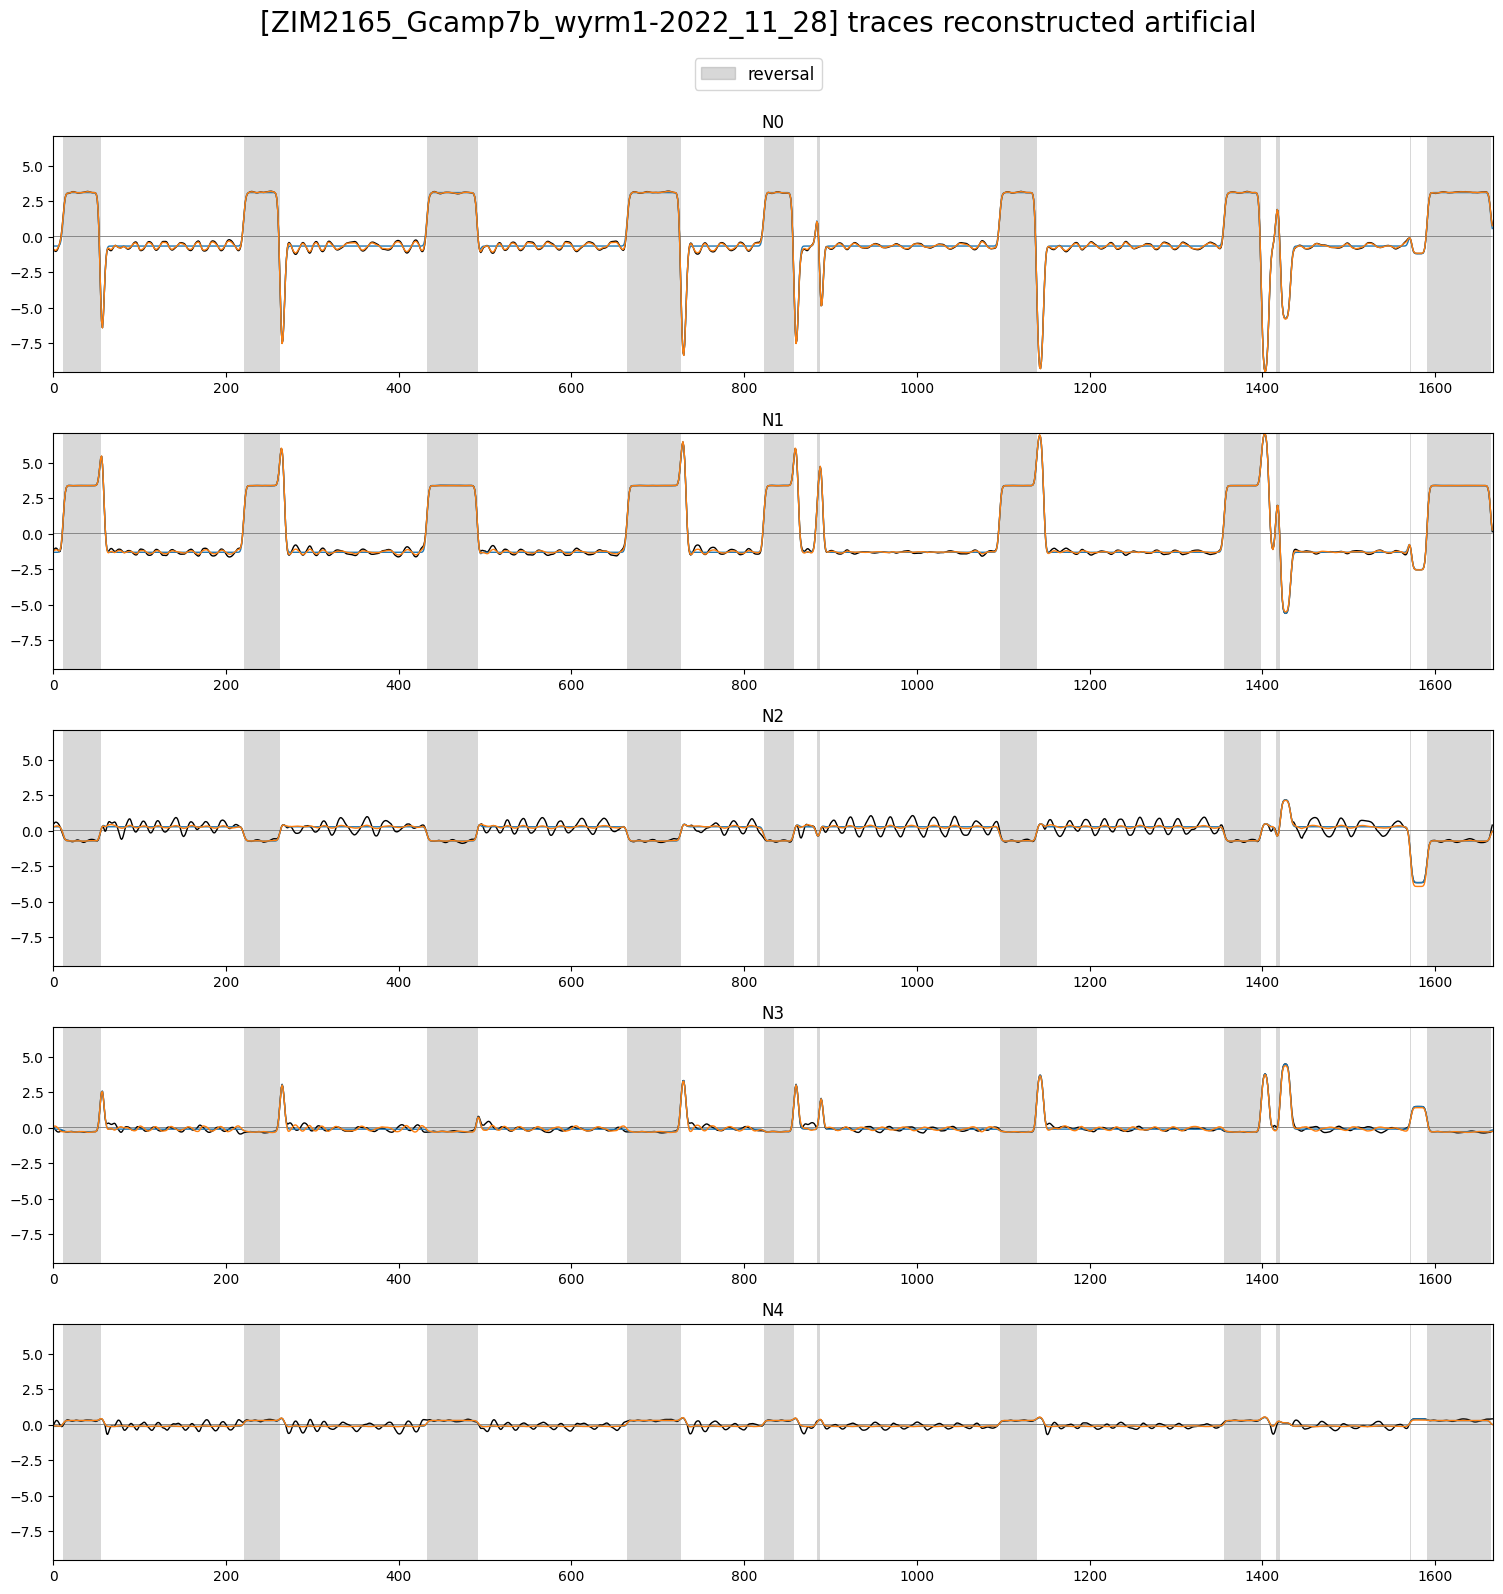

In [46]:
plot_utils.plot_traces([traces[plot_idx][neuron_labels],
						traces_reconstructed[plot_idx][neuron_labels],
						recos_manifold[plot_id][neuron_labels]],
					   discrete_states[plot_id][['REV']],
					   label='reversal',
					   title=f'[{filenames[plot_id]}] traces reconstructed artificial', ylimits=None, plots_per_row=1)

In [47]:
traces_residual_pca = pd.DataFrame(traces[plot_idx].values - recos_manifold[plot_idx].values, columns=traces[plot_idx].columns)

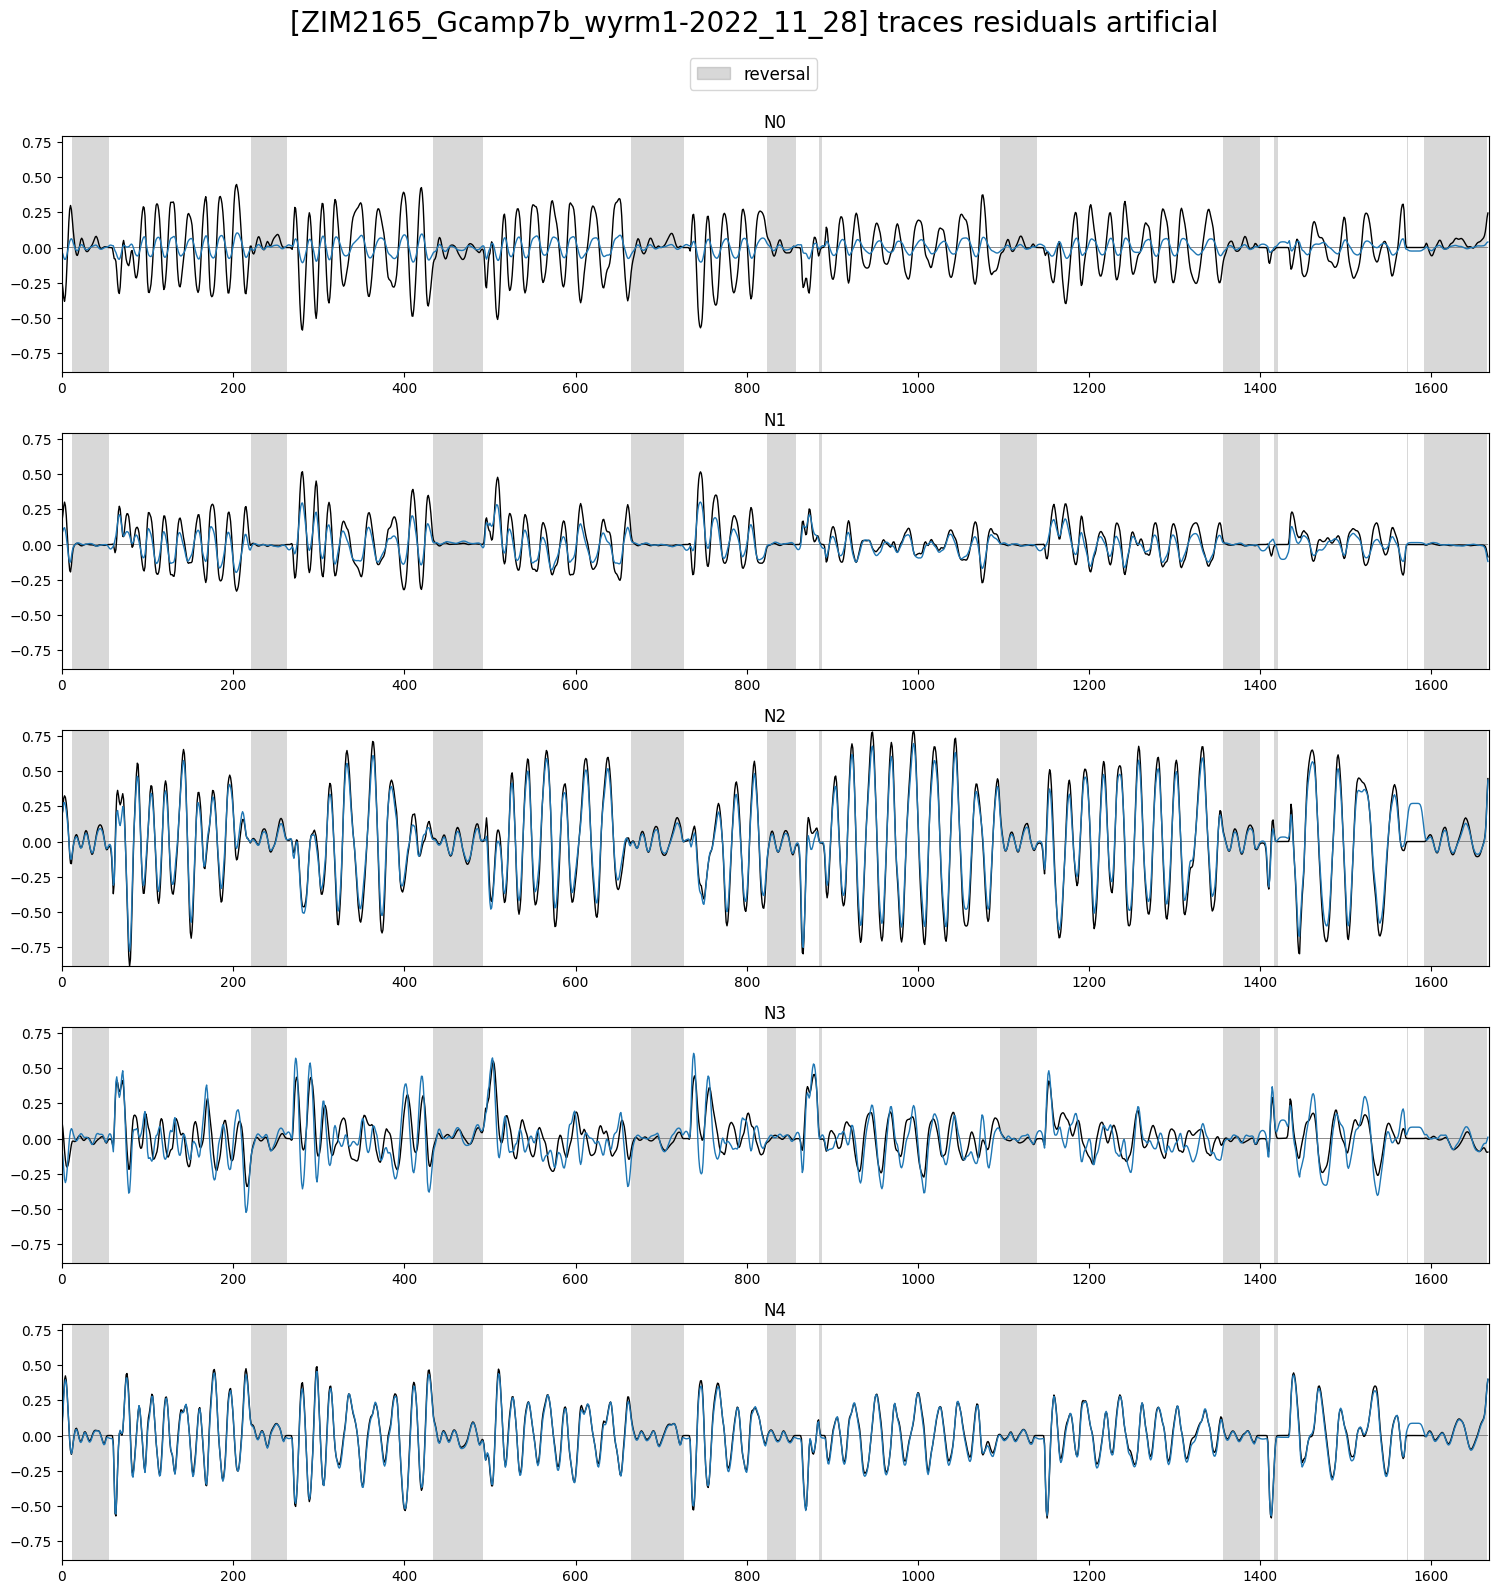

In [48]:
plot_utils.plot_traces([traces_residual[plot_idx][neuron_labels],
						traces_residual_pca[neuron_labels]],
					   discrete_states[plot_id][['REV']],
					   label='reversal',
					   title=f'[{filenames[plot_id]}] traces residuals artificial', ylimits=None, plots_per_row=1)